In [6]:
options(repr.plot.width = 5, repr.plot.height = 3, repr.plot.res = 250)

In [7]:
library('tidymodels')

In [8]:
gss <- read.csv('https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/gss_subset.csv')

gss |> glimpse()

Rows: 75,699
Columns: 8
$ year    <int> 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 19…
$ id      <int> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18,…
$ age     <int> 23, 70, 48, 27, 61, 26, 28, 27, 21, 30, 30, 56, 54, 49, 41, 54…
$ educ    <int> 16, 10, 12, 17, 12, 14, 13, 16, 12, 12, 13, 6, 9, 8, 9, 14, 14…
$ sex     <int> 2, 1, 2, 2, 2, 1, 1, 1, 2, 2, 2, 1, 1, 2, 1, 1, 1, 2, 2, 2, 1,…
$ gunlaw  <int> 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 1, NA…
$ grass   <int> NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA…
$ realinc <dbl> 18951, 24366, 24366, 30458, 50763, 43994, 37226, 13537, 2707, …


In [9]:
gss <- gss |>
    drop_na(realinc, educ, age, sex) |>
    mutate(sex = factor(sex, levels = c(1, 2), labels = c('male', 'female')))

gss |> count(sex)

  sex    n    
1 male   30373
2 female 36908

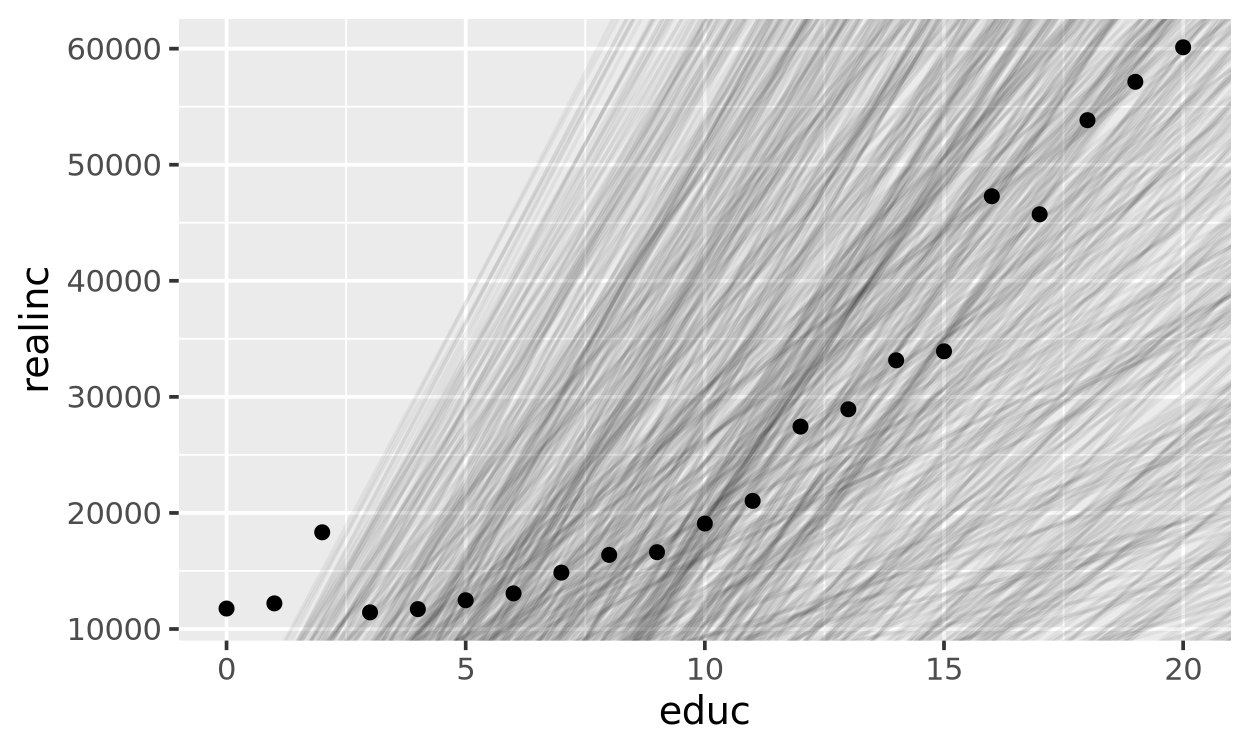

In [21]:
gss |>
    group_by(educ) |>
    summarize(realinc = mean(realinc)) |>
    ggplot(aes(x = educ, y = realinc)) +
    geom_point() +
    geom_abline(data = params, aes(intercept = intercept, slope = slope), alpha = 0.05)

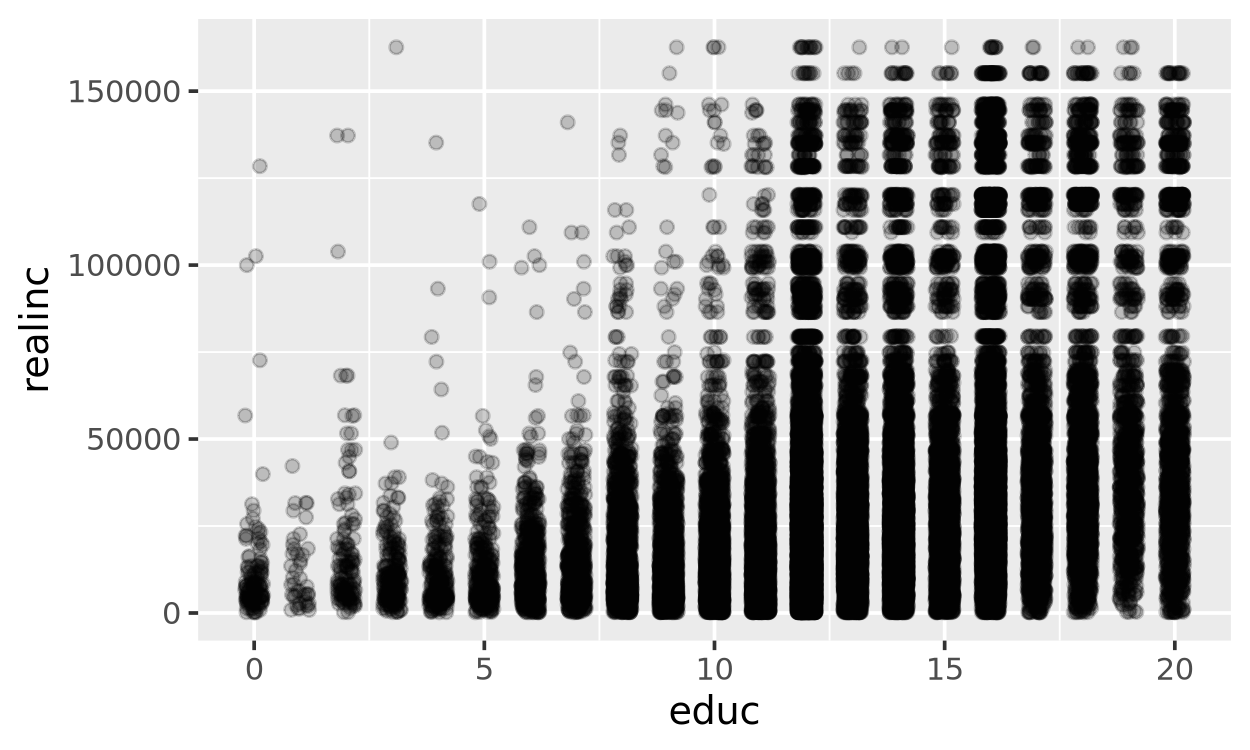

In [14]:
ggplot(gss, aes(x = educ, y = realinc)) +
    geom_point(alpha = 0.2, position = position_jitter(width = 0.2, height = 0.2))

## #1 Write a linear notation for the parameters

A line predicts `realinc` from `educ`:

$$\hat{\text{realinc}} = \text{intercept} + \text{slope} \cdot \text{educ}$$

The two parameters are `intercept` and `slope`. We need a way to choose them.

In [16]:
set.seed(1)

params <- tibble(
    intercept = runif(1000, -60000, 0),
    slope = runif(1000, 0, 8000)
)

params |> glimpse()

Rows: 1,000
Columns: 2
$ intercept <dbl> -44069.4802, -37672.5660, -25628.7982, -5507.5326, -47899.08…
$ slope     <dbl> 4246.47034, 5478.88723, 3066.26715, 7639.90399, 946.85264, 3…


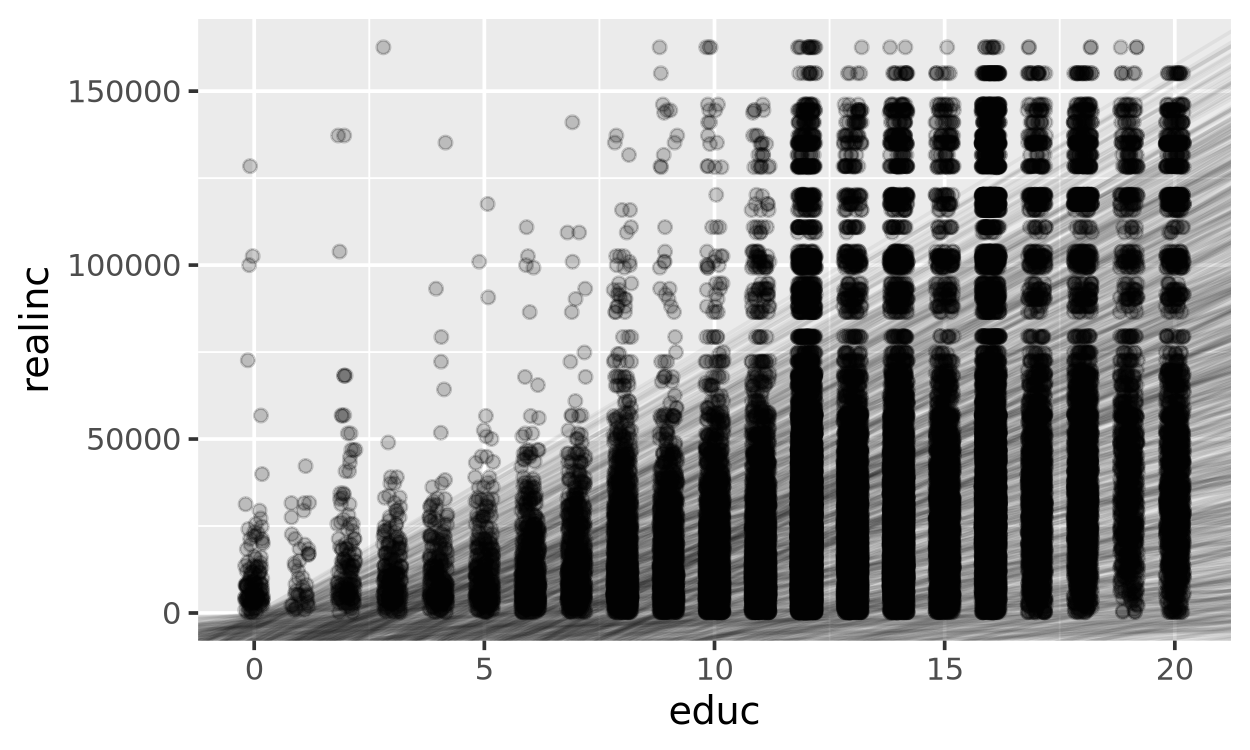

In [17]:
ggplot(gss, aes(x = educ, y = realinc)) +
    geom_point(alpha = 0.2, position = position_jitter(width = 0.2, height = 0.2)) +
    geom_abline(data = params, aes(intercept = intercept, slope = slope), alpha = 0.05)

## #2 Evaluate different parameter values

Draw many random `intercept`/`slope` pairs and score each one with a loss. We use the root mean squared error (RMSE): lower is better.

In [22]:
rmse <- function(intercept, slope, data = gss) {
    sqrt(mean((data$realinc - (intercept + slope * data$educ))^2))
}

params <- params |>
    mutate(rmse = map2_dbl(intercept, slope, rmse))

params |> slice_min(rmse, n = 5)

  intercept slope    sse          rmse    
1 -10881.92 3292.941 5.381973e+13 28282.94
2 -19373.63 3889.192 5.387350e+13 28297.06
3 -12646.11 3326.120 5.395162e+13 28317.57
4  -6129.09 3023.990 5.404688e+13 28342.56
5 -16061.18 3847.725 5.407644e+13 28350.31

## #3 Optimize the parameters

Start from the best random pair and let `optim()` search for the `intercept`/`slope` that minimize the RMSE.

In [23]:
start <- params |> slice_min(rmse, n = 1)

best <- optim(
    par = c(intercept = start$intercept, slope = start$slope),
    fn = function(p) rmse(p[1], p[2])
)

best$par

 intercept      slope 
-14462.433   3575.952 

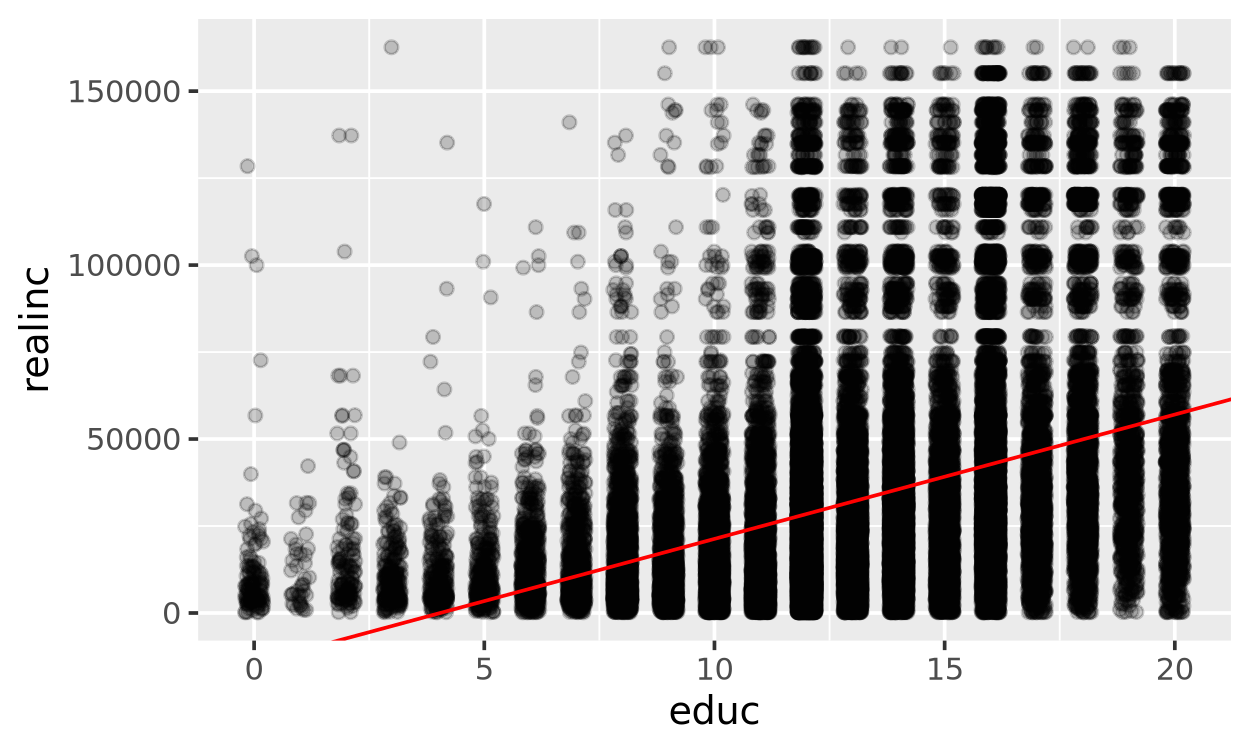

In [20]:
linear_reg() |> fit(realinc ~ educ, data = gss) |> tidy()

ggplot(gss, aes(x = educ, y = realinc)) +
    geom_point(alpha = 0.2, position = position_jitter(width = 0.2, height = 0.2)) +
    geom_abline(intercept = best$par[1], slope = best$par[2], color = 'red')